# 08 評価ルール固定とモデル比較

固定した評価ルールで、RandomForestとXGBoostを比較します。

評価ルール:

- 通常ランダム分割 R2 >= 0.75
- 完全一致配合グループ R2 >= 0.70
- 主PVC + 主可塑剤グループ R2 >= 0.50
- MAEは実務許容範囲を別途決める
- 最大外れ誤差が大きすぎないか確認する


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(project_root / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from plastech.modeling import DEFAULT_TARGET, compare_models_with_rules, evaluation_rules

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["font.family"] = ["Hiragino Sans", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


## 固定した評価ルール

このNotebook以降、モデルの良し悪しは通常ランダム分割だけではなく、グループ評価も含めて判断します。


In [2]:
rules = evaluation_rules()
display(rules)


,rule,metric_key,threshold,direction,purpose
0,通常ランダム分割 R2,random_split_r2,0.75,>=,似た配合を含む補間性能を確認する
1,完全一致配合グループ R2,exact_composition_r2,0.70,>=,完全重複配合による評価漏洩がないか確認する
2,主PVC種 + 主可塑剤グループ R2,primary_pvc_plus_primary_plasticizer_r2,0.50,>=,未知の主要材料系列への汎化性能を確認する
3,MAE,mae,NaN,実務閾値を別途設定,物性単位で実務上許容できる平均誤差か確認する
4,最大外れ誤差,max_abs_error,NaN,実務閾値を別途設定,危険な大外れがないか確認する


## RandomForestとXGBoostを同じ条件で比較する

XGBoostは通常分割で性能が安定するよう、RandomForestより多めの木数で評価します。
グループ評価は5分割の平均です。


In [3]:
comparison = compare_models_with_rules(
    model_names=("random_forest", "xgboost"),
    dataset_name="processed_main",
    target_col=DEFAULT_TARGET,
    random_n_estimators=600,
    grouped_n_estimators=400,
    n_splits=5,
)

display(comparison[[
    "model",
    "evaluation",
    "mean_MAE",
    "mean_RMSE",
    "mean_R2",
    "std_R2",
    "max_abs_error",
    "rule_threshold",
    "rule_pass",
    "rule_note",
]])


,model,evaluation,mean_MAE,mean_RMSE,mean_R2,std_R2,max_abs_error,rule_threshold,rule_pass,rule_note
0,random_forest,通常ランダム分割,1.696992,2.550512,0.768941,NaN,21.102094,0.75,True,通常ランダム分割 R2 >= 0.75
1,random_forest,完全一致配合,1.771583,2.552204,0.762156,0.023894,21.801921,0.7,True,完全一致配合 R2 >= 0.70
2,random_forest,主PVC種,3.215325,4.162097,0.259334,0.512045,21.827629,None,None,参考評価
3,random_forest,主可塑剤,3.541045,4.557728,0.153154,0.109935,17.063163,None,None,参考評価
4,random_forest,主PVC種 + 主可塑剤,3.057637,3.958713,0.476355,0.024188,22.128750,0.5,False,主PVC + 主可塑剤 R2 >= 0.50
5,xgboost,通常ランダム分割,1.780334,2.588670,0.761975,NaN,20.235276,0.75,True,通常ランダム分割 R2 >= 0.75
6,xgboost,完全一致配合,1.915059,2.681822,0.737692,0.017913,20.621180,0.7,True,完全一致配合 R2 >= 0.70
7,xgboost,主PVC種,3.068517,3.959731,0.345806,0.375125,19.783976,None,None,参考評価
8,xgboost,主可塑剤,3.485173,4.314686,0.243710,0.072246,16.414907,None,None,参考評価
9,xgboost,主PVC種 + 主可塑剤,2.872273,3.725679,0.534692,0.064378,20.297407,0.5,True,主PVC + 主可塑剤 R2 >= 0.50


## R2で比較する

点線は各評価ルールの閾値です。通常ランダム分割だけでなく、主PVC + 主可塑剤グループでも閾値を満たすかを確認します。


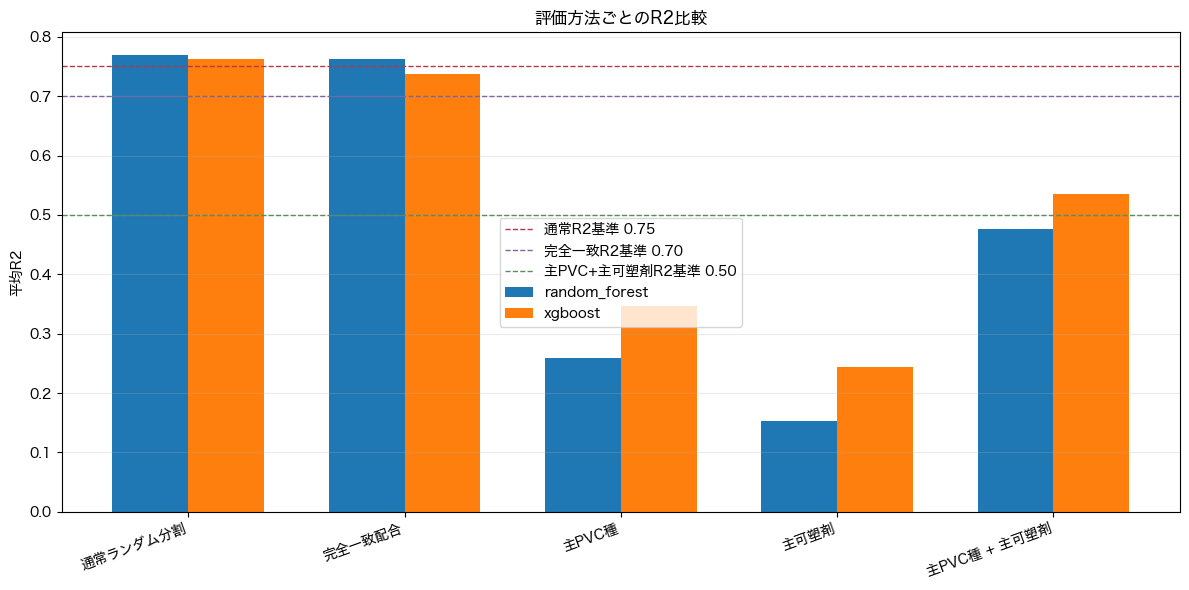

In [4]:
r2_plot = comparison.copy()
fig, ax = plt.subplots(figsize=(12, 6))

labels = r2_plot["evaluation"]
models = r2_plot["model"].unique()
x = range(len(labels.unique()))
width = 0.35
unique_evals = list(r2_plot["evaluation"].unique())

for i, model in enumerate(models):
    model_df = r2_plot[r2_plot["model"] == model].set_index("evaluation").loc[unique_evals]
    offset = (i - 0.5) * width
    ax.bar([v + offset for v in x], model_df["mean_R2"], width=width, label=model)

ax.axhline(0.75, color="#b23a48", linestyle="--", linewidth=1, label="通常R2基準 0.75")
ax.axhline(0.70, color="#8064a2", linestyle="--", linewidth=1, label="完全一致R2基準 0.70")
ax.axhline(0.50, color="#5b8c5a", linestyle="--", linewidth=1, label="主PVC+主可塑剤R2基準 0.50")
ax.set_xticks(list(x))
ax.set_xticklabels(unique_evals, rotation=20, ha="right")
ax.set_ylabel("平均R2")
ax.set_title("評価方法ごとのR2比較")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## MAEと最大外れ誤差を見る

MAEと最大外れ誤差は、まだ実務上の許容値が決まっていません。ここでは値を比較し、許容値を決める材料にします。


model,random_forest,xgboost
evaluation,,
主PVC種,3.215325,3.068517
主PVC種 + 主可塑剤,3.057637,2.872273
主可塑剤,3.541045,3.485173
完全一致配合,1.771583,1.915059
通常ランダム分割,1.696992,1.780334


model,random_forest,xgboost
evaluation,,
主PVC種,21.827629,19.783976
主PVC種 + 主可塑剤,22.128750,20.297407
主可塑剤,17.063163,16.414907
完全一致配合,21.801921,20.621180
通常ランダム分割,21.102094,20.235276


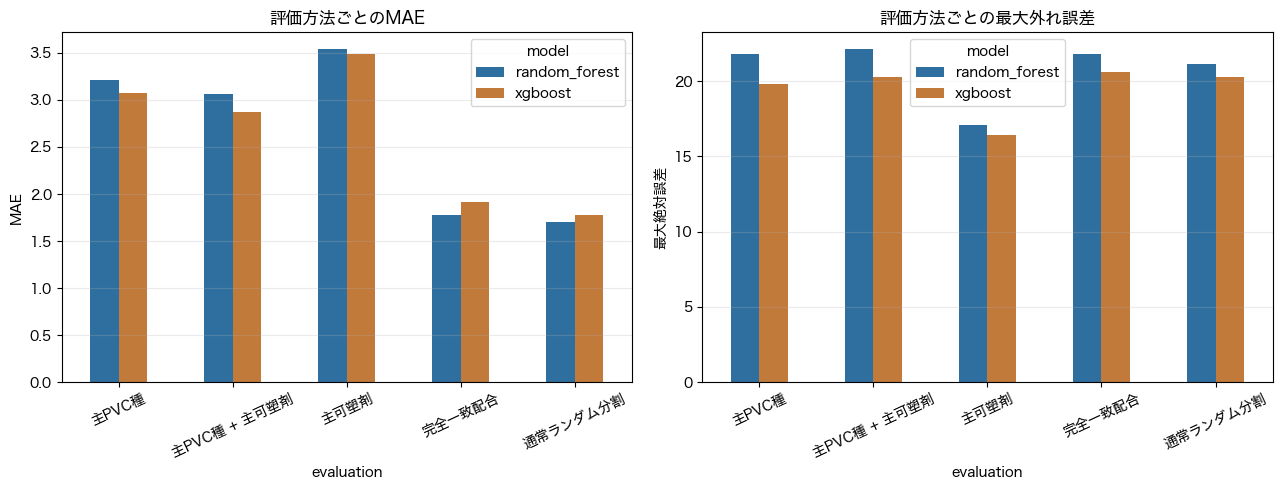

In [5]:
mae_pivot = comparison.pivot(index="evaluation", columns="model", values="mean_MAE")
max_error_pivot = comparison.pivot(index="evaluation", columns="model", values="max_abs_error")

display(mae_pivot)
display(max_error_pivot)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mae_pivot.plot(kind="bar", ax=axes[0], color=["#2f6f9f", "#c27a3a"])
axes[0].set_title("評価方法ごとのMAE")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)

max_error_pivot.plot(kind="bar", ax=axes[1], color=["#2f6f9f", "#c27a3a"])
axes[1].set_title("評価方法ごとの最大外れ誤差")
axes[1].set_ylabel("最大絶対誤差")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


## ルール判定の要約

`rule_pass` がある行は、今回固定した評価ルールに対する合否です。


In [6]:
rule_rows = comparison[comparison["rule_threshold"].notna()].copy()
rule_summary = rule_rows.pivot(index="rule_note", columns="model", values="rule_pass")
display(rule_summary)

pass_count = rule_rows.groupby("model")["rule_pass"].sum().rename("passed_rules")
total_count = rule_rows.groupby("model")["rule_pass"].count().rename("total_rules")
display(pd.concat([pass_count, total_count], axis=1))


model,random_forest,xgboost
rule_note,,
主PVC + 主可塑剤 R2 >= 0.50,False,True
完全一致配合 R2 >= 0.70,True,True
通常ランダム分割 R2 >= 0.75,True,True


,passed_rules,total_rules
model,,
random_forest,2,3
xgboost,3,3


## このNotebookでの判断

- RandomForestは通常ランダム分割と完全一致配合では基準を満たす
- XGBoostも通常ランダム分割と完全一致配合では基準を満たす
- 主PVC + 主可塑剤グループでは、XGBoostが基準を満たすかが重要な比較点
- MAEと最大外れ誤差は、実務許容値を決めてから正式な合否にする
